In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# import zipfile

# zip_path = "/content/drive/MyDrive/AICity23_Track2_NL_Retrieval.zip"

# with zipfile.ZipFile(zip_path, 'r') as z:
#     files = z.namelist()

# print("Total files:", len(files))

# for f in files[:30]:
#     print(f)

In [ ]:
# with zipfile.ZipFile(zip_path, 'r') as z:
#     total_size = sum(info.file_size for info in z.infolist())

# print("Uncompressed size:",
#       total_size / (1024**3), "GB")

In [ ]:
# import zipfile
# from collections import Counter

# zip_path = "/content/drive/MyDrive/AICity23_Track2_NL_Retrieval.zip"

# with zipfile.ZipFile(zip_path, "r") as z:
#     files = z.namelist()

# print("Total files:", len(files))

# # File extensions
# extensions = Counter()

# for f in files:
#     if "." in f.split("/")[-1]:
#         extensions[f.rsplit(".", 1)[-1].lower()] += 1
#     else:
#         extensions["<no extension>"] += 1

# print("\nFile types:")
# for ext, count in extensions.items():
#     print(f"{ext}: {count}")

In [ ]:
# import zipfile

# zip_path = "/content/drive/MyDrive/AICity23_Track2_NL_Retrieval.zip"

# with zipfile.ZipFile(zip_path, "r") as z:
#     json_files = [
#         f for f in z.namelist()
#         if f.lower().endswith(".json")
#     ]

# for f in json_files:
#     print(f)

In [ ]:
from pathlib import Path
import shutil

DRIVE = Path("/content/drive/MyDrive")
VEHICLEIQ = DRIVE / "VehicleIQ"

DATASET = VEHICLEIQ / "datasets" / "AI_CITY_2023_TRACK2_NL_RETRIEVAL"

(DATASET / "raw").mkdir(parents=True, exist_ok=True)
(DATASET / "source").mkdir(parents=True, exist_ok=True)
(DATASET / "processed").mkdir(parents=True, exist_ok=True)

zip_source = DRIVE / "AICity23_Track2_NL_Retrieval.zip"
zip_target = DATASET / "raw" / "AICity23_Track2_NL_Retrieval.zip"

print("Source exists:", zip_source.exists())
print("Target:", zip_target)

Source exists: False
Target: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/raw/AICity23_Track2_NL_Retrieval.zip


In [ ]:
# shutil.move(str(zip_source), str(zip_target))

In [ ]:
# import zipfile
# from pathlib import Path

# zip_path = DATASET / "raw" / "AICity23_Track2_NL_Retrieval.zip"
# source_dir = DATASET / "source"

# with zipfile.ZipFile(zip_path, "r") as z:
#     z.extractall(source_dir)

# print("Extraction complete.")

In [ ]:
!du -sh "/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/source"

17G	/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/source


In [ ]:
!git clone https://github.com/fredfung007/cityflow-nl.git /content/cityflow-nl

Cloning into '/content/cityflow-nl'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (12/12), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 50 (delta 6), reused 1 (delta 1), pack-reused 38 (from 1)
Receiving objects: 100% (50/50), 9.39 MiB | 10.52 MiB/s, done.
Resolving deltas: 100% (9/9), done.


In [ ]:
from pathlib import Path

SOURCE = Path(
    "/content/drive/MyDrive/VehicleIQ/datasets/"
    "AI_CITY_2023_TRACK2_NL_RETRIEVAL/source"
)

print("Source exists:", SOURCE.exists())

for p in [
    SOURCE / "data",
    SOURCE / "data" / "extract_vdo_frms.py",
    SOURCE / "data" / "train-tracks.json",
    SOURCE / "data" / "test-tracks.json",
    SOURCE / "data" / "test-queries.json",
]:
    print(p, "->", p.exists())

Source exists: True
/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/source/data -> True
/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/source/data/extract_vdo_frms.py -> True
/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/source/data/train-tracks.json -> True
/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/source/data/test-tracks.json -> True
/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/source/data/test-queries.json -> True


In [ ]:
SCRIPT = "/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/source/data/extract_vdo_frms.py"

with open(SCRIPT, "r") as f:
    print(f.read())

import os
import cv2
import argparse


def check_and_create(folder_path):
    if not os.path.isdir(folder_path):
        os.makedirs(folder_path)
    return folder_path


def main(args):
    seq_list = os.listdir(args.data_root)

    for seq_name in seq_list:
        path_data = os.path.join(args.data_root, seq_name)
        path_vdo = os.path.join(path_data, 'vdo.avi')
        path_images = os.path.join(path_data, 'img1')
        check_and_create(path_images)

        vidcap = cv2.VideoCapture(path_vdo)
        success, image = vidcap.read()

        count = 1
        while success:
            path_image = os.path.join(path_images, '%06d.jpg' % count)
            cv2.imwrite(path_image, image)
            success, image = vidcap.read()
            print('Data path: %s: Frame #%06d' % (path_data, count))
            count += 1


if __name__ == '__main__':
    print("Loading parameters...")
    parser = argparse.ArgumentParser(description='Extract video frames')
    parser.add_argument

In [ ]:
import os
import json
import cv2
import time
from pathlib import Path
from collections import defaultdict
from tqdm.auto import tqdm


In [ ]:
VEHICLEIQ = Path("/content/drive/MyDrive/VehicleIQ")

DATASET_ROOT = (
    VEHICLEIQ
    / "datasets"
    / "AI_CITY_2023_TRACK2_NL_RETRIEVAL"
)

SOURCE_ROOT = DATASET_ROOT / "source" / "data"
PROCESSED_ROOT = DATASET_ROOT / "processed"

TRAIN_TRACKS_JSON = SOURCE_ROOT / "train-tracks.json"
TEST_TRACKS_JSON = SOURCE_ROOT / "test-tracks.json"
TEST_QUERIES_JSON = SOURCE_ROOT / "test-queries.json"

TRAIN_OUTPUT = PROCESSED_ROOT / "train" / "tracks"
TEST_OUTPUT = PROCESSED_ROOT / "test" / "tracks"
METADATA_OUTPUT = PROCESSED_ROOT / "metadata"

In [ ]:
for folder in [
    TRAIN_OUTPUT,
    TEST_OUTPUT,
    METADATA_OUTPUT
]:
    folder.mkdir(parents=True, exist_ok=True)

In [ ]:
def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


print("Loading annotations...")

train_tracks = load_json(TRAIN_TRACKS_JSON)
test_tracks = load_json(TEST_TRACKS_JSON)
test_queries = load_json(TEST_QUERIES_JSON)

print(f"Train tracks : {len(train_tracks)}")
print(f"Test tracks  : {len(test_tracks)}")
print(f"Test queries : {len(test_queries)}")

Loading annotations...
Train tracks : 2155
Test tracks  : 184
Test queries : 184


In [ ]:
def normalize_frame_path(frame_path):
    """
    Example:

    ./train/S01/c003/img1/000028.jpg

    becomes:

    train/S01/c003/img1/000028.jpg
    """

    frame_path = frame_path.replace("\\", "/")

    while frame_path.startswith("./"):
        frame_path = frame_path[2:]

    return frame_path


In [ ]:
def get_video_path(frame_path):
    """
    Convert:

    train/S01/c003/img1/000028.jpg

    into:

    SOURCE_ROOT/train/S01/c003/vdo.avi
    """

    normalized = normalize_frame_path(frame_path)

    parts = Path(normalized).parts

    # Expected:
    # train / S01 / c003 / img1 / 000028.jpg
    # validation / S02 / c006 / img1 / 000001.jpg

    if len(parts) < 5:
        raise ValueError(f"Unexpected frame path: {frame_path}")

    split = parts[0]
    scene = parts[1]
    camera = parts[2]

    video_path = SOURCE_ROOT / split / scene / camera / "vdo.avi"

    return video_path


In [ ]:
def get_frame_number(frame_path):
    """
    000028.jpg -> 28
    """

    name = Path(normalize_frame_path(frame_path)).stem

    return int(name)

In [ ]:
def build_required_frames(track_dict):
    """
    Groups required frames by video.

    Returns:

    {
        video_path: {
            frame_number: [
                {
                    track_id,
                    bbox,
                    original_frame_path,
                    ...
                }
            ]
        }
    }
    """

    required = defaultdict(lambda: defaultdict(list))

    for track_id, track in track_dict.items():

        frames = track.get("frames", [])
        boxes = track.get("boxes", [])

        if len(frames) != len(boxes):
            print(
                f"WARNING: {track_id}: "
                f"{len(frames)} frames but {len(boxes)} boxes"
            )

        count = min(len(frames), len(boxes))

        for i in range(count):

            frame_path = frames[i]
            bbox = boxes[i]

            try:
                video_path = get_video_path(frame_path)
                frame_number = get_frame_number(frame_path)
            except Exception as e:
                print(
                    f"Skipping invalid frame reference "
                    f"{frame_path}: {e}"
                )
                continue

            required[str(video_path)][frame_number].append({
                "track_id": track_id,
                "bbox": bbox,
                "frame_path": normalize_frame_path(frame_path)
            })

    return required


In [ ]:
print("\nBuilding frame index...")

train_required = build_required_frames(train_tracks)
test_required = build_required_frames(test_tracks)

print(f"Train videos required: {len(train_required)}")
print(f"Test videos required : {len(test_required)}")



Building frame index...
Train videos required: 23
Test videos required : 28


In [ ]:
def crop_bbox(frame, bbox):
    """
    Bounding box format from CityFlow:

    [x, y, width, height]
    """

    if len(bbox) != 4:
        return None

    x, y, w, h = [int(round(v)) for v in bbox]

    if w <= 0 or h <= 0:
        return None

    height, width = frame.shape[:2]

    x1 = max(0, x)
    y1 = max(0, y)

    x2 = min(width, x + w)
    y2 = min(height, y + h)

    if x2 <= x1 or y2 <= y1:
        return None

    crop = frame[y1:y2, x1:x2]

    if crop.size == 0:
        return None

    return crop


In [ ]:
def process_split(required_frames, output_root, split_name):

    stats = {
        "videos": 0,
        "videos_missing": 0,
        "frames_requested": 0,
        "frames_read": 0,
        "crops_saved": 0,
        "crops_skipped_existing": 0,
        "invalid_crops": 0,
        "failed_writes": 0,
        "tracks_processed": set()
    }

    print("\n" + "=" * 70)
    print(f"PROCESSING {split_name.upper()}")
    print("=" * 70)

    video_items = list(required_frames.items())

    for video_path_str, frame_map in tqdm(
        video_items,
        desc=f"{split_name} videos"
    ):

        video_path = Path(video_path_str)

        stats["videos"] += 1

        if not video_path.exists():

            print(
                f"\nWARNING: video does not exist:\n"
                f"{video_path}"
            )

            stats["videos_missing"] += 1
            continue

        requested_frames = set(frame_map.keys())

        stats["frames_requested"] += len(requested_frames)

        max_required_frame = max(requested_frames)

        cap = cv2.VideoCapture(str(video_path))

        if not cap.isOpened():

            print(
                f"\nWARNING: could not open:\n"
                f"{video_path}"
            )

            stats["videos_missing"] += 1
            continue

        current_frame = 0

        while current_frame < max_required_frame:

            success, frame = cap.read()

            if not success:
                break

            current_frame += 1

            if current_frame not in frame_map:
                continue

            stats["frames_read"] += 1

            annotations = frame_map[current_frame]

            for ann in annotations:

                track_id = ann["track_id"]
                bbox = ann["bbox"]

                track_dir = output_root / track_id
                track_dir.mkdir(parents=True, exist_ok=True)

                output_name = (
                    f"frame_{current_frame:06d}.jpg"
                )

                output_path = track_dir / output_name

                stats["tracks_processed"].add(track_id)

                # Resume support
                if output_path.exists():
                    stats["crops_skipped_existing"] += 1
                    continue

                crop = crop_bbox(frame, bbox)

                if crop is None:
                    stats["invalid_crops"] += 1
                    continue

                success_write = cv2.imwrite(
                    str(output_path),
                    crop,
                    [
                        cv2.IMWRITE_JPEG_QUALITY,
                        95
                    ]
                )

                if success_write:
                    stats["crops_saved"] += 1
                else:
                    stats["failed_writes"] += 1

        cap.release()

    return stats

In [ ]:
# start_time = time.time()

# train_stats = process_split(
#     train_required,
#     TRAIN_OUTPUT,
#     "train"
# )

# # ============================================================
# # 8. PROCESS TEST
# # ============================================================

# test_stats = process_split(
#     test_required,
#     TEST_OUTPUT,
#     "test"
# )

# elapsed = time.time() - start_time



In [ ]:
def create_processed_metadata(
    tracks,
    output_root,
    split
):

    processed = {}

    for track_id, track in tracks.items():

        record = {
            "vehicle_id": track_id,
            "split": split,
            "source": {
                "frames": track.get("frames", []),
                "boxes": track.get("boxes", [])
            },
            "images": [],
            "descriptions": track.get("nl", []),
            "descriptions_other_views": track.get(
                "nl_other_views",
                []
            )
        }

        frames = track.get("frames", [])

        for frame_path in frames:

            normalized = normalize_frame_path(
                frame_path
            )

            frame_number = get_frame_number(
                normalized
            )

            crop_path = (
                output_root
                / track_id
                / f"frame_{frame_number:06d}.jpg"
            )

            if crop_path.exists():

                relative_path = crop_path.relative_to(
                    PROCESSED_ROOT
                )

                record["images"].append({
                    "frame_number": frame_number,
                    "source_frame": normalized,
                    "crop_path": str(
                        relative_path
                    ).replace("\\", "/")
                })

        processed[track_id] = record

    return processed


In [ ]:
# print("\nCreating metadata...")

# train_metadata = create_processed_metadata(
#     train_tracks,
#     TRAIN_OUTPUT,
#     "train"
# )

# test_metadata = create_processed_metadata(
#     test_tracks,
#     TEST_OUTPUT,
#     "test"
# )


In [ ]:
with open(
    METADATA_OUTPUT / "train_tracks.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        train_metadata,
        f,
        indent=2
    )


with open(
    METADATA_OUTPUT / "test_tracks.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        test_metadata,
        f,
        indent=2
    )


with open(
    METADATA_OUTPUT / "test_queries.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        test_queries,
        f,
        indent=2
    )



NameError: name 'train_metadata' is not defined

In [ ]:
summary = {
    "dataset": "AI_CITY_2023_TRACK2_NL_RETRIEVAL",

    "source": {
        "source_root": str(SOURCE_ROOT)
    },

    "tracks": {
        "train": len(train_tracks),
        "test": len(test_tracks),
        "test_queries": len(test_queries)
    },

    "processing": {
        "train_videos": train_stats["videos"],
        "test_videos": test_stats["videos"],

        "train_frames_requested":
            train_stats["frames_requested"],

        "test_frames_requested":
            test_stats["frames_requested"],

        "train_crops_saved":
            train_stats["crops_saved"],

        "test_crops_saved":
            test_stats["crops_saved"],

        "train_existing_skipped":
            train_stats["crops_skipped_existing"],

        "test_existing_skipped":
            test_stats["crops_skipped_existing"],

        "train_invalid_crops":
            train_stats["invalid_crops"],

        "test_invalid_crops":
            test_stats["invalid_crops"],

        "train_failed_writes":
            train_stats["failed_writes"],

        "test_failed_writes":
            test_stats["failed_writes"],

        "train_missing_videos":
            train_stats["videos_missing"],

        "test_missing_videos":
            test_stats["videos_missing"]
    },

    "runtime_seconds": elapsed
}


with open(
    METADATA_OUTPUT / "dataset_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        summary,
        f,
        indent=2
    )


NameError: name 'train_stats' is not defined

In [ ]:
# print("\n")
# print("=" * 70)
# print("VEHICLEIQ DATASET PREPROCESSING COMPLETE")
# print("=" * 70)

# print(f"\nTrain tracks       : {len(train_tracks)}")
# print(f"Test tracks        : {len(test_tracks)}")
# print(f"Test queries       : {len(test_queries)}")

# print("\nTRAIN")
# print(f"  Videos processed : {train_stats['videos']}")
# print(f"  Frames requested : {train_stats['frames_requested']}")
# print(f"  Crops saved      : {train_stats['crops_saved']}")
# print(f"  Existing skipped : {train_stats['crops_skipped_existing']}")
# print(f"  Invalid crops    : {train_stats['invalid_crops']}")
# print(f"  Missing videos   : {train_stats['videos_missing']}")

# print("\nTEST")
# print(f"  Videos processed : {test_stats['videos']}")
# print(f"  Frames requested : {test_stats['frames_requested']}")
# print(f"  Crops saved      : {test_stats['crops_saved']}")
# print(f"  Existing skipped : {test_stats['crops_skipped_existing']}")
# print(f"  Invalid crops    : {test_stats['invalid_crops']}")
# print(f"  Missing videos   : {test_stats['videos_missing']}")

# print(f"\nRuntime: {elapsed / 60:.2f} minutes")

# print("\nProcessed dataset:")
# print(PROCESSED_ROOT)

In [ ]:
import json
from pathlib import Path
from collections import Counter
import numpy as np

BASE = Path(
    "/content/drive/MyDrive/VehicleIQ/datasets/"
    "AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed"
)

with open(BASE / "metadata/train_tracks.json", "r") as f:
    train = json.load(f)

with open(BASE / "metadata/test_tracks.json", "r") as f:
    test = json.load(f)

# Number of images per track
train_counts = [
    len(record["images"])
    for record in train.values()
]

test_counts = [
    len(record["images"])
    for record in test.values()
]

print("TRAIN")
print("Tracks:", len(train_counts))
print("Total crops:", sum(train_counts))
print("Min crops/track:", min(train_counts))
print("Max crops/track:", max(train_counts))
print("Mean crops/track:", np.mean(train_counts))
print("Median crops/track:", np.median(train_counts))

print("\nTEST")
print("Tracks:", len(test_counts))
print("Total crops:", sum(test_counts))
print("Min crops/track:", min(test_counts))
print("Max crops/track:", max(test_counts))
print("Mean crops/track:", np.mean(test_counts))
print("Median crops/track:", np.median(test_counts))

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [ ]:
print("\nTRAIN DESCRIPTION COUNTS")

description_counts = Counter()

for record in train.values():
    description_counts[len(record["descriptions"])] += 1

print(description_counts)


TRAIN DESCRIPTION COUNTS


NameError: name 'train' is not defined

In [ ]:
for i, (track_id, record) in enumerate(train.items()):

    print("\nTrack:", track_id)
    print("Images:", len(record["images"]))

    print("Descriptions:")
    for d in record["descriptions"]:
        print(" -", d)

    if i == 4:
        break


Track: b06c903c-a25d-45fe-b0d5-294f72e34023
Images: 7
Descriptions:
 - A red sedan drives forward.
 - A red midsize sedan keep straight.
 - A red car drove through an intersection.

Track: 3a02a86d-154b-4ee2-bd5e-a0811113a9d8
Images: 20
Descriptions:
 - A red sedan keeping straight.
 - A red sedan drives forward.
 - A red midsize sedan keep straight.

Track: eb184f7c-35c7-4f3e-af52-1db57fb087d4
Images: 41
Descriptions:
 - A red sedan runs down the street followed by a green van.
 - A red sedan keeping straight.
 - A maroon sedan runs down the road followed by a green vehicle.

Track: abd32535-8acb-49c5-8da4-9e904d263d8c
Images: 18
Descriptions:
 - A white pickup goes straight.
 - A white truck runs down the street.
 - White dodge ram pickup truck going straight through an intersection.

Track: 3819f85b-103a-4f0b-b0f1-49e6b2fedb68
Images: 19
Descriptions:
 - A white truck runs down the street.
 - A pickup truck is going straight.
 - A white pickup goes straight.


In [ ]:
import json
from pathlib import Path
import numpy as np

BASE = Path(
    "/content/drive/MyDrive/VehicleIQ/datasets/"
    "AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed"
)

TRAIN_METADATA = BASE / "metadata" / "train_tracks.json"
SAMPLED_METADATA = BASE / "metadata" / "train_sampled_8.json"

with open(TRAIN_METADATA, "r", encoding="utf-8") as f:
    train = json.load(f)

MAX_IMAGES = 8

sampled = {}

total_original = 0
total_sampled = 0

for vehicle_id, record in train.items():

    images = record["images"]

    total_original += len(images)

    if len(images) <= MAX_IMAGES:
        selected = images
    else:
        indices = np.linspace(
            0,
            len(images) - 1,
            MAX_IMAGES,
            dtype=int
        )

        selected = [images[i] for i in indices]

    sampled[vehicle_id] = {
        **record,
        "images": selected,
        "sampling": {
            "method": "uniform_temporal",
            "max_images": MAX_IMAGES,
            "original_count": len(images),
            "selected_count": len(selected)
        }
    }

    total_sampled += len(selected)

SAMPLED_METADATA.parent.mkdir(
    parents=True,
    exist_ok=True
)

with open(
    SAMPLED_METADATA,
    "w",
    encoding="utf-8"
) as f:
    json.dump(sampled, f, indent=2)

print("Sampling complete")
print("------------------")
print("Vehicles:", len(sampled))
print("Original crops:", total_original)
print("Sampled crops:", total_sampled)
print("Average sampled images/vehicle:", total_sampled / len(sampled))
print("Saved:", SAMPLED_METADATA)

JSONDecodeError: Expecting value: line 1 column 1 (char 0)


Vehicle: b40d30e2-9da5-47ef-ac6b-be9adf356924
  A silver wagon turns left out of a parking lot.
  A silver MPV turns left.
  A gray SUV making a left turn.
Image: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/b40d30e2-9da5-47ef-ac6b-be9adf356924/frame_002007.jpg


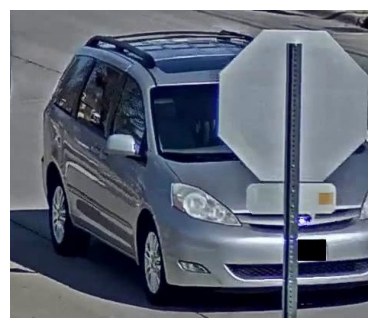


Vehicle: 23a4f3b1-a663-447f-b90d-db21d163c824
  In front of him was a brown sedan car.
  A black SUV stops behind another vehicle to wait for turning right.
  A black wagon stops at an intersection.
Image: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/23a4f3b1-a663-447f-b90d-db21d163c824/frame_003407.jpg


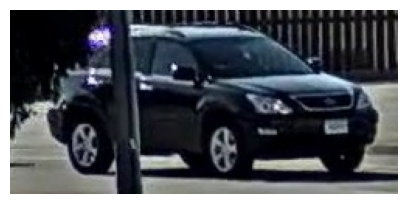


Vehicle: bea8d80d-731e-423d-8a8f-239a4effa801
  Looks like a minivan.
  A blue SUV stops at the intersection after another red vehicle.
  Blue SUV goes down the street following a silver SUV.
Image: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/bea8d80d-731e-423d-8a8f-239a4effa801/frame_002242.jpg


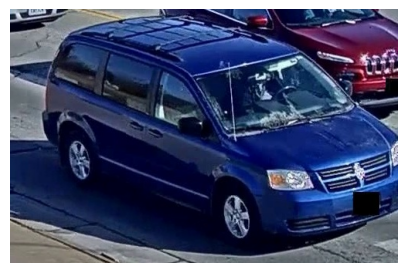


Vehicle: e79564fb-bd0f-4088-95b1-ec43ad3e7eb1
  A midsize white vehicle slow down while passing  a bus.
  A white sedan keeping straight down the street.
  A white sedan slowing down and turning right on an intersection.
Image: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/e79564fb-bd0f-4088-95b1-ec43ad3e7eb1/frame_000780.jpg


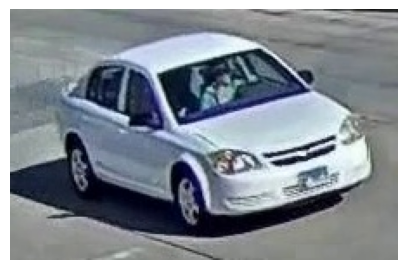


Vehicle: 1dab341d-33a6-4e05-acac-03ba7fad0f37
  A silver sedan runs down the street.
  A gray sedan runs down the street.
  A gray sedan passes by a parking lot.
Image: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/1dab341d-33a6-4e05-acac-03ba7fad0f37/frame_003468.jpg


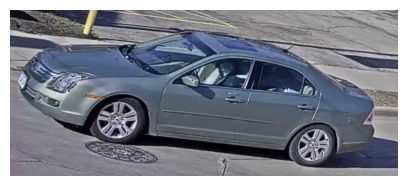


Vehicle: 6cee4f7e-ff88-45d5-afdd-6da6525b2640
  A white pickup truck runs down the street followed by a gray vehicle.
  White crossover going straight.
  A white pickup turns left at a three-way intersection.
Image: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/6cee4f7e-ff88-45d5-afdd-6da6525b2640/frame_002738.jpg


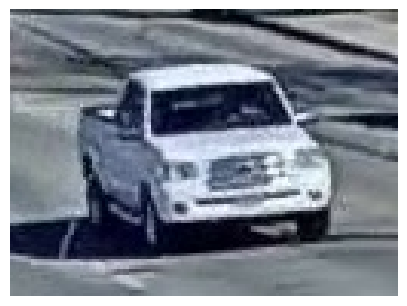

In [ ]:
import json
import random
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

BASE = Path(
    "/content/drive/MyDrive/VehicleIQ/datasets/"
    "AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed"
)

with open(BASE / "metadata/train_sampled_8.json") as f:
    data = json.load(f)

samples = random.sample(list(data.items()), 6)

for vehicle_id, record in samples:

    print("\nVehicle:", vehicle_id)

    for description in record["descriptions"]:
        print(" ", description)

    image_info = random.choice(record["images"])

    image_path = BASE / image_info["crop_path"]

    print("Image:", image_path)

    img = Image.open(image_path)

    plt.figure(figsize=(5, 4))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

In [ ]:
!pip install -q transformers accelerate sentencepiece

import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

PyTorch: 2.11.0+cpu
CUDA: False


In [ ]:
from pathlib import Path
import json

BASE = Path(
    "/content/drive/MyDrive/VehicleIQ/datasets/"
    "AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed"
)

sampled_file = BASE / "metadata" / "train_sampled_8.json"

print("Exists:", sampled_file.exists())

if sampled_file.exists():
    with open(sampled_file) as f:
        sampled = json.load(f)

    print("Vehicles:", len(sampled))

    counts = [
        len(v["images"])
        for v in sampled.values()
    ]

    print("Total sampled images:", sum(counts))
    print("Average:", sum(counts) / len(counts))
    print("Min:", min(counts))
    print("Max:", max(counts))

Exists: True
Vehicles: 2155
Total sampled images: 17025
Average: 7.900232018561485
Min: 5
Max: 8


In [ ]:
!pip install -q -U transformers accelerate faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 18.5 MB/s eta 0:00:00


In [ ]:
import torch
import transformers
import faiss

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("FAISS:", faiss.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Transformers: 5.15.0
FAISS: 1.15.0
CUDA: True
GPU: Tesla T4


In [ ]:
import torch
from transformers import AutoProcessor, AutoModel

MODEL_ID = "google/siglip2-base-patch16-224"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

processor = AutoProcessor.from_pretrained(MODEL_ID)

model = AutoModel.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16
)

model = model.to(device)
model.eval()

print("Model loaded.")
print("Device:", device)

preprocessor_config.json:   0%|          | 0.00/394 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/253 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


tokenizer_config.json:   0%|          | 0.00/47.2k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 34.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

Model loaded.
Device: cuda


Vehicle: b06c903c-a25d-45fe-b0d5-294f72e34023
Image: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/train/tracks/b06c903c-a25d-45fe-b0d5-294f72e34023/frame_000001.jpg
Descriptions:
 - A red sedan drives forward.
 - A red midsize sedan keep straight.
 - A red car drove through an intersection.


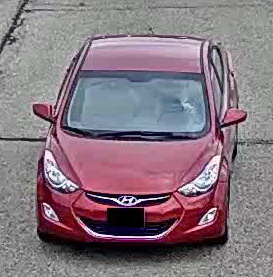

In [ ]:
from PIL import Image
import json
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/VehicleIQ/datasets/"
    "AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed"
)

with open(BASE / "metadata/train_sampled_8.json") as f:
    sampled = json.load(f)

vehicle_id, record = next(iter(sampled.items()))

image_info = record["images"][0]

image_path = BASE / image_info["crop_path"]

image = Image.open(image_path).convert("RGB")

print("Vehicle:", vehicle_id)
print("Image:", image_path)
print("Descriptions:")

for text in record["descriptions"]:
    print(" -", text)

display(image)

In [ ]:
from transformers import AutoProcessor, AutoModel
import torch

MODEL_ID = "google/siglip2-base-patch16-224"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

processor = AutoProcessor.from_pretrained(MODEL_ID)

model = AutoModel.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16
).to(device)

model.eval()

print("Model:", MODEL_ID)
print("Device:", device)

preprocessor_config.json:   0%|          | 0.00/394 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/253 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


tokenizer_config.json:   0%|          | 0.00/47.2k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 34.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

Model: google/siglip2-base-patch16-224
Device: cuda


In [ ]:
import torch
import torch.nn.functional as F


def encode_images(images):
    """
    images: PIL image or list of PIL images

    Returns:
        normalized image embeddings
        shape: [N, 768]
    """

    if not isinstance(images, list):
        images = [images]

    inputs = processor(
        images=images,
        return_tensors="pt"
    )

    inputs = {
        k: v.to(device)
        for k, v in inputs.items()
        if torch.is_tensor(v)
    }

    with torch.no_grad():
        output = model.get_image_features(**inputs)

    # Current Transformers returns BaseModelOutputWithPooling.
    if hasattr(output, "pooler_output"):
        embeddings = output.pooler_output
    else:
        embeddings = output

    embeddings = F.normalize(
        embeddings,
        p=2,
        dim=-1
    )

    return embeddings


def encode_texts(texts):
    """
    texts: string or list of strings

    Returns:
        normalized text embeddings
        shape: [N, 768]
    """

    if isinstance(texts, str):
        texts = [texts]

    inputs = processor(
        text=texts,
        padding="max_length",
        truncation=True,
        return_tensors="pt"
    )

    inputs = {
        k: v.to(device)
        for k, v in inputs.items()
        if torch.is_tensor(v)
    }

    with torch.no_grad():
        output = model.get_text_features(**inputs)

    if hasattr(output, "pooler_output"):
        embeddings = output.pooler_output
    else:
        embeddings = output

    embeddings = F.normalize(
        embeddings,
        p=2,
        dim=-1
    )

    return embeddings

In [ ]:
image_embedding = encode_images(image)

text_embeddings = encode_texts(
    record["descriptions"]
)

similarities = (
    image_embedding @ text_embeddings.T
)

print("Image:", image_embedding.shape)
print("Text:", text_embeddings.shape)

print("\nSimilarity:")
for text, score in zip(
    record["descriptions"],
    similarities[0]
):
    print(
        f"{score.item():.4f}  {text}"
    )

Image: torch.Size([1, 768])
Text: torch.Size([3, 768])

Similarity:
0.0538  After turning left.
0.0348  A gray hatchback going straight down the street with two cars following it.
0.0564  A black SUV runs down the street followed by another black vehicle.


In [ ]:
print(type(image_output))
print(type(text_output))

# print("\nIMAGE OUTPUT:")
# print(image_output)

# print("\nTEXT OUTPUT:")
# print(text_output)

NameError: name 'image_output' is not defined

In [ ]:
test_texts = [
    "a red sedan",
    "a white pickup truck",
    "a blue bus",
    "a motorcycle",
    "a building",
    "a person"
]

test_embeddings = encode_texts(test_texts)

scores = (
    image_embedding @ test_embeddings.T
)[0]

print("Query comparison:\n")

for text, score in zip(
    test_texts,
    scores
):
    print(
        f"{score.item():.4f}  {text}"
    )

Query comparison:

0.0493  a red sedan
0.0373  a white pickup truck
0.0478  a blue bus
0.0293  a motorcycle
0.0294  a building
0.0388  a person


In [ ]:
import json
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/VehicleIQ/datasets/"
    "AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed"
)

with open(
    BASE / "metadata/train_sampled_8.json",
    "r",
    encoding="utf-8"
) as f:
    sampled = json.load(f)

print("Vehicles:", len(sampled))

total_images = sum(
    len(r["images"])
    for r in sampled.values()
)

print("Representative images:", total_images)

Vehicles: 2155
Representative images: 17025


In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

BATCH_SIZE = 32

vehicle_ids = []
vehicle_embeddings = []

# Build a flat list:
# (vehicle_id, image_path)
image_items = []

for vehicle_id, record in sampled.items():

    for image_info in record["images"]:

        image_path = BASE / image_info["crop_path"]

        image_items.append(
            (
                vehicle_id,
                image_path
            )
        )

print("Total images:", len(image_items))

Total images: 17025


In [ ]:
from pathlib import Path
import json

BASE = Path(
    "/content/drive/MyDrive/VehicleIQ/datasets/"
    "AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed"
)

METADATA = BASE / "metadata"

print("BASE:", BASE)
print("Exists:", BASE.exists())
print("Metadata:", METADATA.exists())

BASE: /content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed
Exists: True
Metadata: True


In [ ]:
print(list(METADATA.iterdir()))

[PosixPath('/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/metadata/train_tracks.json'), PosixPath('/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/metadata/test_tracks.json'), PosixPath('/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/metadata/test_queries.json'), PosixPath('/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/metadata/dataset_summary.json'), PosixPath('/content/drive/MyDrive/VehicleIQ/datasets/AI_CITY_2023_TRACK2_NL_RETRIEVAL/processed/metadata/train_sampled_8.json')]


In [ ]:
with open(
    METADATA / "train_sampled_8.json",
    "r",
    encoding="utf-8"
) as f:
    sampled = json.load(f)

print("Vehicles:", len(sampled))

total_images = sum(
    len(record["images"])
    for record in sampled.values()
)

print("Representative images:", total_images)

Vehicles: 2155
Representative images: 17025


In [ ]:
!nvidia-smi

Tue Aug 11 06:26:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   77C    P0             34W /   70W |    1225MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
print("CUDA:", torch.cuda.is_available())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

NameError: name 'torch' is not defined

In [ ]:
import numpy as np
import torch
from PIL import Image
from tqdm.auto import tqdm
import time

VEHICLE_BATCH_SIZE = 8
MAX_FRAMES_PER_VEHICLE = 8

vehicle_ids = list(sampled.keys())

vehicle_embeddings = []
processed_vehicle_ids = []

start_time = time.time()

for start in tqdm(
    range(
        0,
        len(vehicle_ids),
        VEHICLE_BATCH_SIZE
    ),
    desc="Encoding vehicles"
):

    batch_vehicle_ids = vehicle_ids[
        start:start + VEHICLE_BATCH_SIZE
    ]

    batch_images = []
    batch_mapping = []

    for vehicle_id in batch_vehicle_ids:

        record = sampled[vehicle_id]

        selected_images = record["images"][
            :MAX_FRAMES_PER_VEHICLE
        ]

        for image_info in selected_images:

            image_path = (
                BASE /
                image_info["crop_path"]
            )

            try:

                image = Image.open(
                    image_path
                ).convert("RGB")

                batch_images.append(image)
                batch_mapping.append(
                    vehicle_id
                )

            except Exception as e:

                print(
                    f"\nFailed: {image_path}"
                )
                print(e)

    if not batch_images:
        continue

    # Encode all images belonging to this vehicle batch
    embeddings = encode_images(
        batch_images
    )

    embeddings = (
        embeddings
        .cpu()
        .numpy()
        .astype(np.float32)
    )

    # Aggregate frame embeddings
    offset = 0

    for vehicle_id in batch_vehicle_ids:

        num_images = min(
            len(
                sampled[vehicle_id]["images"]
            ),
            MAX_FRAMES_PER_VEHICLE
        )

        vehicle_frame_embeddings = (
            embeddings[
                offset:
                offset + num_images
            ]
        )

        offset += num_images

        if len(vehicle_frame_embeddings) == 0:
            continue

        # Mean pooling
        vehicle_embedding = (
            vehicle_frame_embeddings
            .mean(axis=0)
        )

        # Normalize after averaging
        norm = np.linalg.norm(
            vehicle_embedding
        )

        if norm > 0:
            vehicle_embedding /= norm

        vehicle_embeddings.append(
            vehicle_embedding
        )

        processed_vehicle_ids.append(
            vehicle_id
        )

print("\n================================")
print("Embedding extraction complete")
print("================================")
print(
    "Vehicles:",
    len(processed_vehicle_ids)
)

print(
    "Embedding shape:",
    np.asarray(
        vehicle_embeddings
    ).shape
)

print(
    "Runtime:",
    time.time() - start_time,
    "seconds"
)

Encoding vehicles:   0%|          | 0/270 [00:00<?, ?it/s]